## RSM8413 Group Assignment 2

### Section 1: Data Preprocessing

In [1]:
# import packages and libraries
import pandas as pd
import numpy as np
import openpyxl
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [2]:
# get the raw data from the excel file
df_raw = pd.read_excel('ebayAuctions.xlsx', sheet_name="eBay auctions")

In [3]:
df_raw.head()

,Category,Currency,sellerRating,Duration,endDay,ClosePrice,OpenPrice,Competitive?,Unnamed: 8
0,Music/Movie/Game,US,37727.0,7.0,Mon,0.01,0.01,0.0,NaN
1,Music/Movie/Game,US,37727.0,7.0,Mon,4.26,0.01,1.0,NaN
2,SportingGoods,US,34343.0,1.0,Fri,0.11,0.01,1.0,NaN
3,SportingGoods,US,27132.0,5.0,Mon,17.01,0.99,1.0,NaN
4,SportingGoods,US,27132.0,5.0,Mon,19.02,0.99,1.0,NaN


In [4]:
df_raw.shape

(1975, 9)

In [5]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1975 entries, 0 to 1974
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Category      1972 non-null   object 
 1   Currency      1972 non-null   object 
 2   sellerRating  1972 non-null   float64
 3   Duration      1972 non-null   float64
 4   endDay        1972 non-null   object 
 5   ClosePrice    1972 non-null   float64
 6   OpenPrice     1972 non-null   float64
 7   Competitive?  1974 non-null   float64
 8   Unnamed: 8    1 non-null      float64
dtypes: float64(6), object(3)
memory usage: 139.0+ KB


In [6]:
# from the shape and info
# we can see that there are some non-data rows and a column need to be dropped

df_clean = df_raw.iloc[:1972, :8].copy()

In [7]:
# check missing values
df_clean.isna().sum()

Category        0
Currency        0
sellerRating    0
Duration        0
endDay          0
ClosePrice      0
OpenPrice       0
Competitive?    0
dtype: int64

In [8]:
# rename the "Competitive?" column name

df_clean = df_clean.rename(columns={"Competitive?": "Competitive"})

In [9]:
# check the duplicates
print(df_clean.duplicated().sum()) 

346


There are 346 duplicated rows. Since there are no seller ID, auction ID or product ID, these rows might be records for different auctions. Thus, we keep these records. 

In [10]:
# check the data types
df_clean.dtypes

Category         object
Currency         object
sellerRating    float64
Duration        float64
endDay           object
ClosePrice      float64
OpenPrice       float64
Competitive     float64
dtype: object

In [11]:
# check the predictors unique values for categorical variables
print(df_clean['Category'].unique())
print(df_clean['Duration'].unique())
print(df_clean['Currency'].unique())
print(df_clean['endDay'].unique())

['Music/Movie/Game' 'SportingGoods' 'Business/Industrial' 'Automotive'
 'Collectibles' 'Home/Garden' 'Jewelry' 'Electronics' 'Coins/Stamps'
 'Pottery/Glass' 'Computer' 'Toys/Hobbies' 'Clothing/Accessories'
 'Antique/Art/Craft' 'Books' 'Health/Beauty' 'EverythingElse'
 'Photography']
[ 7.  1.  5.  3. 10.]
['US' 'EUR' 'GBP']
['Mon' 'Fri' 'Sun' 'Tue' 'Wed' 'Thu' 'Sat']


In [12]:
# change Duration from float to string, make it clean
df_clean['Duration'] = df_clean['Duration'].astype('int')
df_clean['Duration'] = df_clean['Duration'].astype('str')
df_clean['Competitive'] = df_clean['Competitive'].astype('int')

In [13]:
assert df_clean['Competitive'].isin([0, 1]).all()

In [14]:
# create dummy variables for Category, Currency, Duration, endDay
cat_cols = ['Category', 'Currency', 'Duration', 'endDay']
df_model = pd.get_dummies(df_clean, columns=cat_cols, dtype=int)

In [15]:
# check the columns names after creating dummy variables
print(df_model.columns.tolist())

['sellerRating', 'ClosePrice', 'OpenPrice', 'Competitive', 'Category_Antique/Art/Craft', 'Category_Automotive', 'Category_Books', 'Category_Business/Industrial', 'Category_Clothing/Accessories', 'Category_Coins/Stamps', 'Category_Collectibles', 'Category_Computer', 'Category_Electronics', 'Category_EverythingElse', 'Category_Health/Beauty', 'Category_Home/Garden', 'Category_Jewelry', 'Category_Music/Movie/Game', 'Category_Photography', 'Category_Pottery/Glass', 'Category_SportingGoods', 'Category_Toys/Hobbies', 'Currency_EUR', 'Currency_GBP', 'Currency_US', 'Duration_1', 'Duration_10', 'Duration_3', 'Duration_5', 'Duration_7', 'endDay_Fri', 'endDay_Mon', 'endDay_Sat', 'endDay_Sun', 'endDay_Thu', 'endDay_Tue', 'endDay_Wed']


In [16]:
# check if dummy variables are correctly assigned
for p in ['Category_', 'Currency_', 'Duration_', 'endDay_']:
    assert (df_model.filter(like=p).sum(axis=1) == 1).all()


In [17]:
# reorder the columns in a natural way
num_cols = ['sellerRating', 'ClosePrice', 'OpenPrice']
category_cols = [c for c in df_model.columns if c.lower().startswith('category_')]
curr_cols = [c for c in df_model.columns if c.lower().startswith('currency_')]
dur_cols = ['Duration_1', 'Duration_3', 'Duration_5', 'Duration_7', 'Duration_10']
endday_cols = ['endDay_Sun', 'endDay_Mon', 'endDay_Tue', 'endDay_Wed', 'endDay_Thu', 'endDay_Fri', 'endDay_Sat']
df_model = df_model[num_cols + category_cols + curr_cols + dur_cols + endday_cols + ['Competitive']]

In [18]:
assert df_model.shape == (1972, 37)

In [19]:
df_model.to_csv('ebayAuctions_processed.csv', index=False)

In [20]:
# set X and y
X = df_model.drop(columns=['Competitive'])
y = df_model['Competitive']

In [21]:
assert X.shape[1] == 36

In [22]:
# train test split, 40% test
seed = 42
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, stratify=y, random_state=seed)

In [23]:
# save the train and test sets to csv files
X_train.to_csv('X_train.csv', index=False)
X_test.to_csv('X_test.csv', index=False)
y_train.to_csv('y_train.csv', index=False)
y_test.to_csv('y_test.csv', index=False)

In [24]:
#check the shape of the train and test sets
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(1183, 36) (789, 36) (1183,) (789,)


In [25]:
# check the percentage of the target variable
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

Competitive
1    0.540152
0    0.459848
Name: proportion, dtype: float64
Competitive
1    0.541191
0    0.458809
Name: proportion, dtype: float64


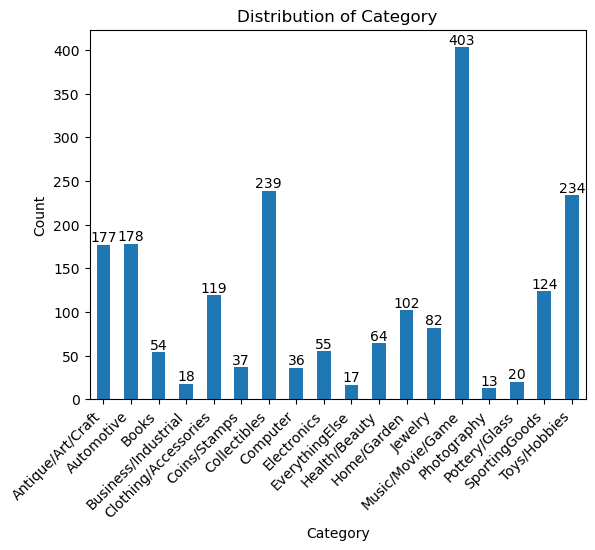

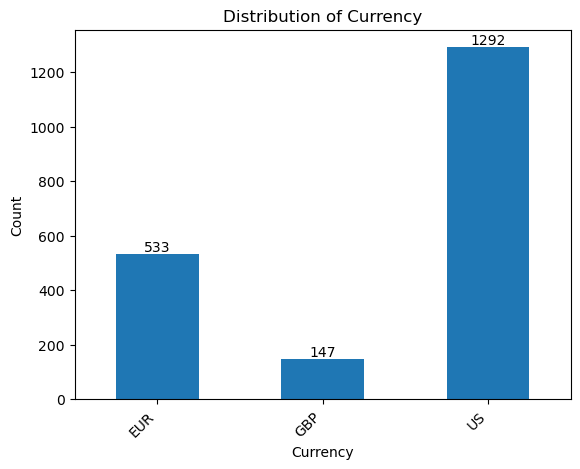

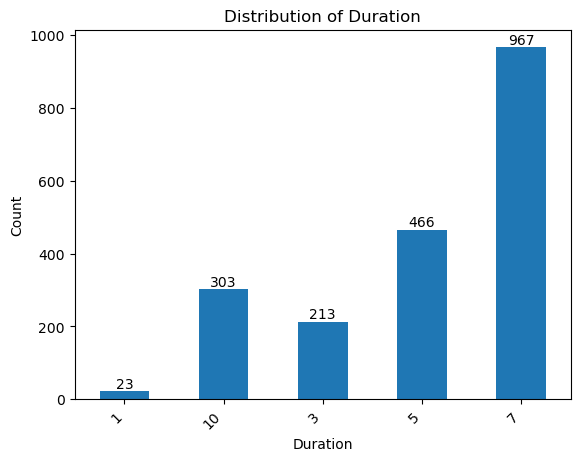

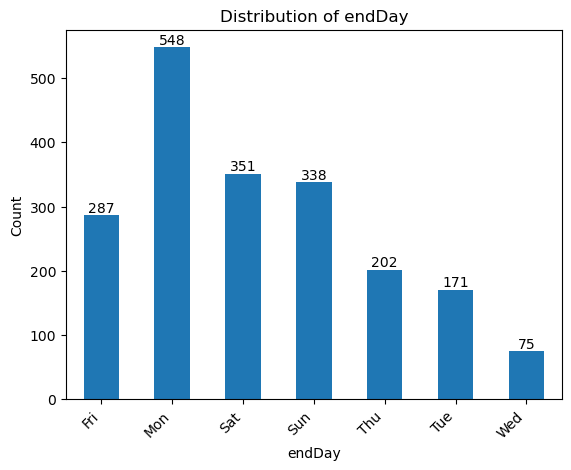

In [26]:
# check the distribution of the predictors
for c in ['Category', 'Currency', 'Duration', 'endDay']:
    ax = df_clean.groupby(c).size().plot(kind='bar')
    ax.bar_label(ax.containers[0])
    plt.xlabel(c)
    plt.ylabel('Count')
    plt.title(f'Distribution of {c}')
    plt.xticks(rotation=45, ha='right')
    plt.show()

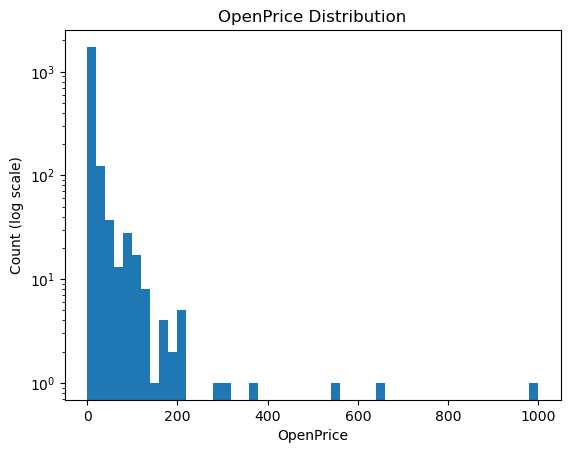

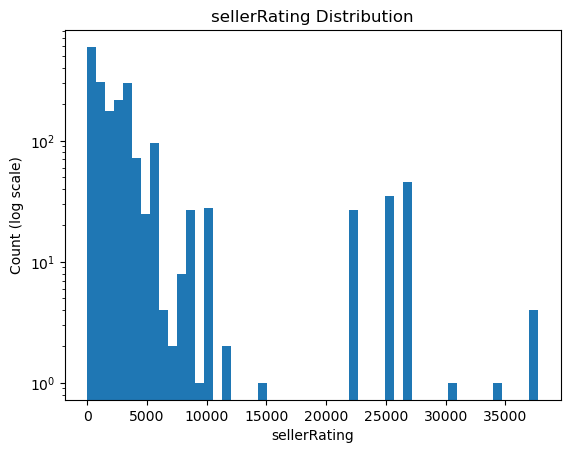

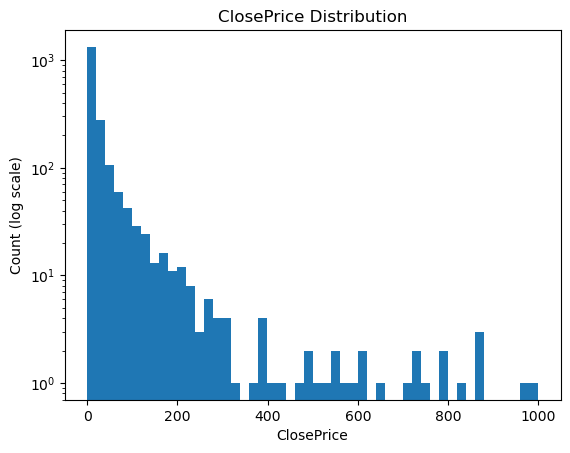

In [27]:
# using log y to show extreme values

for v in ['OpenPrice', 'sellerRating', 'ClosePrice']:
    df_clean[v].plot(kind='hist', bins=50, logy=True, title=f'{v} Distribution')
    plt.xlabel(v)
    plt.ylabel('Count (log scale)')
    plt.show()

In [28]:
# Check the percentage of competitive auctions for each categorical predictor
summary_tables = {}
for c in ['Category', 'Currency', 'Duration', 'endDay']:
    t = pd.crosstab(df_clean[c], df_clean['Competitive'])
    t['Total'] = t.sum(axis=1)
    t['% Competitive'] = (t[1] / t['Total'] * 100).round(1)
    summary_tables[c] = t.sort_values('Total', ascending=False)

In [29]:
# reorder in a more natural way
summary_tables['Duration'] = summary_tables['Duration'].reindex(['1', '3', '5', '7', '10'])
summary_tables['endDay'] = summary_tables['endDay'].reindex(['Sun', 'Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat'])

In [30]:
# display the tables
for c, t in summary_tables.items():
    print(c)
    display(t)

Category


Competitive,0,1,Total,% Competitive
Category,,,,
Music/Movie/Game,160,243,403,60.3
Collectibles,101,138,239,57.7
Toys/Hobbies,110,124,234,53.0
Automotive,115,63,178,35.4
Antique/Art/Craft,77,100,177,56.5
SportingGoods,34,90,124,72.6
Clothing/Accessories,59,60,119,50.4
Home/Garden,35,67,102,65.7
Jewelry,52,30,82,36.6


Currency


Competitive,0,1,Total,% Competitive
Currency,,,,
US,621,671,1292,51.9
EUR,239,294,533,55.2
GBP,46,101,147,68.7


Duration


Competitive,0,1,Total,% Competitive
Duration,,,,
1,11,12,23,52.2
3,117,96,213,45.1
5,146,320,466,68.7
7,494,473,967,48.9
10,138,165,303,54.5


endDay


Competitive,0,1,Total,% Competitive
endDay,,,,
Sun,174,164,338,48.5
Mon,179,369,548,67.3
Tue,80,91,171,53.2
Wed,39,36,75,48.0
Thu,80,122,202,60.4
Fri,153,134,287,46.7
Sat,201,150,351,42.7
